# 01 · Common Voice Turkish: exploratory data analysis

Clip durations, sentence lengths, speakers and vocabulary of the official `train` / `dev` / `test`
splits. All loading and statistics logic lives in `src/data/`; this notebook only analyses and plots.

Figures are saved to `results/figures/`. The split table is also produced by
`python -m src.data.stats` (`results/data_summary.md`).

In [1]:
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd

from src.config import REPO_ROOT, load_config, resolve_path
from src.data.common_voice import SPLITS, load_audio, load_split
from src.data.normalization import normalize_text
from src.data.stats import summarize_split

warnings.filterwarnings("ignore", module="tqdm")  # IProgress warning from librosa's deps

config = load_config(REPO_ROOT / "configs/data.yaml")
root = resolve_path(config["dataset"]["root"])
FIG_DIR = REPO_ROOT / "results/figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

clips = {split: load_split(root, split) for split in SPLITS}
df = pd.DataFrame(
    [
        {
            "split": split,
            "client_id": c.client_id,
            "duration_s": c.duration_s,
            "sentence": c.sentence,
            "words": len(c.sentence.split()),
            "gender": c.gender or "unspecified",
            "age": c.age or "unspecified",
        }
        for split, items in clips.items()
        for c in items
    ]
)
df.groupby("split", sort=False).size()

split
train    41465
dev      11864
test     11874
dtype: int64

## Split overview

In [2]:
summary = {split: summarize_split(items) for split, items in clips.items()}
overview = pd.DataFrame(
    {
        split: {
            "clips": s["clips"],
            "speakers": s["speakers"],
            "hours": round(s["hours"], 2),
            "largest speaker share": f"{s['top_speaker_share']:.1%}",
            "median duration (s)": s["duration_s"]["median"],
            "median words": s["words_per_sentence"]["median"],
        }
        for split, s in summary.items()
    }
)
overview

,train,dev,test
clips,41465,11864,11874
speakers,28,163,1500
hours,45.27,12.35,14.54
largest speaker share,20.2%,2.5%,0.4%
median duration (s),3.276,3.276,4.104
median words,4.0,4.0,5.0


## Clip durations

,count,mean,std,min,5%,50%,95%,max
split,,,,,,,,
train,41465.0,3.93,1.99,0.65,1.80,3.28,8.06,13.32
dev,11864.0,3.75,1.64,0.76,1.84,3.28,7.06,11.02
test,11874.0,4.41,1.65,1.33,2.30,4.10,7.67,13.86


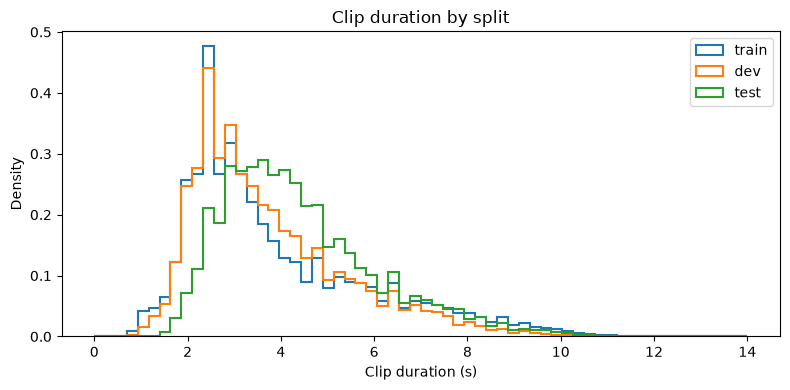

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
for split in SPLITS:
    ax.hist(
        df.loc[df.split == split, "duration_s"],
        bins=60,
        range=(0, 14),
        histtype="step",
        density=True,
        linewidth=1.5,
        label=split,
    )
ax.set_xlabel("Clip duration (s)")
ax.set_ylabel("Density")
ax.set_title("Clip duration by split")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "clip_durations.png", dpi=150)
df.groupby("split", sort=False)["duration_s"].describe(percentiles=[0.05, 0.5, 0.95]).round(2)

## Sentence length (words)

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
train,41465.0,5.03,3.53,1.0,2.0,4.0,7.0,20.0
dev,11864.0,4.97,3.29,1.0,2.0,4.0,7.0,19.0
test,11874.0,5.65,3.21,1.0,3.0,5.0,7.0,20.0


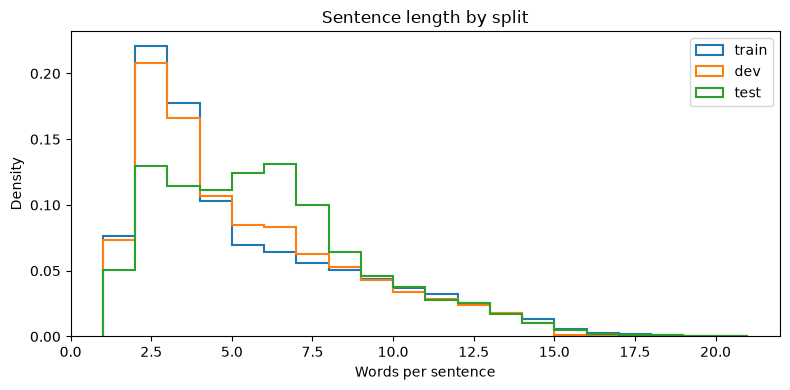

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for split in SPLITS:
    ax.hist(
        df.loc[df.split == split, "words"],
        bins=range(1, 22),
        histtype="step",
        density=True,
        linewidth=1.5,
        label=split,
    )
ax.set_xlabel("Words per sentence")
ax.set_ylabel("Density")
ax.set_title("Sentence length by split")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "sentence_lengths.png", dpi=150)
df.groupby("split", sort=False)["words"].describe().round(2)

## Speakers

Common Voice keeps the splits speaker-disjoint. With few heavy contributors this leaves very few
speakers in `train`.

speakers shared by train/dev: 0
speakers shared by train/test: 0
speakers shared by dev/test: 0


top 5 train speakers cover 62.4% of train clips


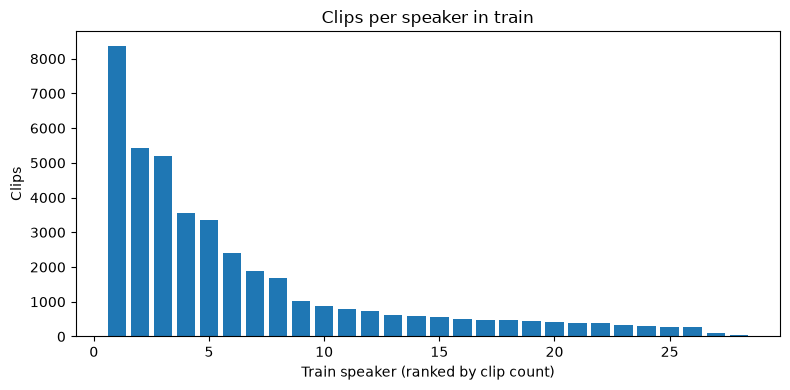

In [5]:
for a, b in [("train", "dev"), ("train", "test"), ("dev", "test")]:
    shared = set(df.loc[df.split == a, "client_id"]) & set(df.loc[df.split == b, "client_id"])
    print(f"speakers shared by {a}/{b}: {len(shared)}")

per_speaker = df[df.split == "train"].client_id.value_counts()
cumulative = per_speaker.cumsum() / per_speaker.sum()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, len(per_speaker) + 1), per_speaker.values)
ax.set_xlabel("Train speaker (ranked by clip count)")
ax.set_ylabel("Clips")
ax.set_title("Clips per speaker in train")
fig.tight_layout()
fig.savefig(FIG_DIR / "train_clips_per_speaker.png", dpi=150)
print(f"top 5 train speakers cover {cumulative.iloc[4]:.1%} of train clips")

## Gender and age (clips, % within split)

In [6]:
display(pd.crosstab(df.gender, df.split, normalize="columns")[list(SPLITS)].mul(100).round(1))
pd.crosstab(df.age, df.split, normalize="columns")[list(SPLITS)].mul(100).round(1)

split,train,dev,test
gender,,,
female_feminine,42.1,14.1,6.2
male_masculine,43.6,51.0,27.4
unspecified,14.3,34.9,66.4


split,train,dev,test
age,,,
eighties,8.3,0.0,0.0
fifties,10.3,4.9,1.8
fourties,2.2,5.8,3.9
seventies,6.8,0.0,0.0
sixties,33.7,2.8,0.5
teens,0.0,5.7,3.1
thirties,6.8,17.0,11.2
twenties,17.7,33.6,19.5
unspecified,14.3,30.4,60.1


## Vocabulary and normalization

Effect of `normalize_text` on the references and how much of the test vocabulary is never
seen in the train transcripts (relevant for a sentence-level read-speech corpus).

In [7]:
df["normalized"] = df.sentence.map(normalize_text)
vocab = {
    split: Counter(w for s in df.loc[df.split == split, "normalized"] for w in s.split())
    for split in SPLITS
}
rows = {}
for split in SPLITS:
    test_like = vocab[split]
    oov_types = [w for w in test_like if w not in vocab["train"]]
    rows[split] = {
        "word tokens": sum(test_like.values()),
        "word types": len(test_like),
        "types not in train (%)": round(100 * len(oov_types) / len(test_like), 1),
        "tokens not in train (%)": round(
            100 * sum(test_like[w] for w in oov_types) / sum(test_like.values()), 1
        ),
    }
pd.DataFrame(rows)

,train,dev,test
word tokens,208665.0,59001.0,67099.0
word types,44750.0,18989.0,20809.0
types not in train (%),0.0,37.5,41.3
tokens not in train (%),0.0,13.2,14.9


In [8]:
print("sentences repeated within train:", df[df.split == "train"].sentence.duplicated().sum())
print(
    "sentences shared train/test:",
    len(set(df.loc[df.split == "train", "sentence"]) & set(df.loc[df.split == "test", "sentence"])),
)
pd.DataFrame(vocab["train"].most_common(15), columns=["word", "count"]).T

sentences repeated within train: 0
sentences shared train/test: 0


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
word,bir,ve,bu,ne,de,da,çok,için,daha,sonra,ben,mi,o,olarak,kadar
count,5573,3420,3174,1864,1343,1197,1106,1089,1025,961,915,842,830,786,780


## Audio sanity check

Decode one clip at 16 kHz and compare with `clip_durations.tsv`.

In [9]:
sample = clips["test"][0]
audio = load_audio(sample.audio_path, sampling_rate=config["audio"]["sampling_rate"])
print(sample.sentence)
print(f"samples={len(audio)}  decoded={len(audio) / 16000:.3f}s  metadata={sample.duration_s:.3f}s")

Belgrad da aynı derecede kuşkulu görünüyor.
samples=59136  decoded=3.696s  metadata=3.696s


## Findings

- **Speaker diversity in `train` is very low:** 28 speakers, the largest one has 20.2% of the
  clips and the top 5 cover 62.4%. `dev` has 163 and `test` 1,500 speakers. The splits are
  speaker- and sentence-disjoint, so test WER measures generalization to unseen voices.
- **Demographic shift:** `train` is dominated by older speakers (sixties 33.7%, eighties 8.3%),
  while most `test` clips have no declared age (60.1%) and the declared ones are mostly
  twenties/thirties. Gender is mostly undeclared in `test` (66.4%).
- **Short clips:** median 3.3 s (train) / 4.1 s (test), max 13.9 s. No clip exceeds Whisper's
  30 s window, so no splitting is needed for this corpus.
- **Short sentences:** median 4 (train) / 5 (test) words, max 20.
- **Open vocabulary:** after normalization 41.3% of test word types (14.9% of tokens) never
  occur in the train transcripts, as expected for a sentence corpus of an agglutinative language.
- Decoding at 16 kHz matches the metadata duration exactly.